# 1. Compreensão do problema

## 1.1 Contextualização

A qualidade de um vinho está relacionada a um conjunto de características que podem ser avaliadas por meio de análises físico-químicas, como teor alcoólico, acidez, densidade, pH, concentração de sulfatos e dióxido de enxofre, entre outras.

Nesse contexto, a análise de dados pode contribuir para identificar padrões e relações entre essas características e a qualidade atribuída aos vinhos, permitindo explorar a utilização de modelos de aprendizado de máquina para apoiar a classificação de sua qualidade.

## 1.2 Objetivo do projeto

O objetivo deste projeto é analisar os dados físico-químicos dos vinhos e desenvolver modelos de aprendizado de máquina capazes de identificar vinhos classificados como de alta qualidade.

Para isso, serão utilizadas técnicas de análise exploratória de dados (EDA), pré-processamento e modelagem preditiva, seguidas da avaliação e comparação dos resultados obtidos pelos modelos.

## 1.3 Definição do problema analítico

O problema será tratado como uma tarefa de **classificação binária supervisionada**.

A variável original `quality`, que representa a avaliação de qualidade do vinho, será transformada em uma variável categórica denominada `high_quality`, seguindo o critério:

- **0 – Qualidade não elevada:** vinhos com avaliação inferior a 7;
- **1 – Alta qualidade:** vinhos com avaliação igual ou superior a 7.

Dessa forma, o modelo terá como objetivo identificar a qual dessas duas categorias pertence cada observação, utilizando como variáveis explicativas as características físico-químicas disponíveis na base de dados.

## 1.4 Abordagem analítica

O desenvolvimento será organizado nas seguintes etapas:

- Compreensão e exploração da base de dados;
- Análise da distribuição das variáveis e identificação de possíveis padrões;
- Preparação dos dados para utilização nos modelos;
- Desenvolvimento de modelos de classificação;
- Avaliação do desempenho por meio de métricas apropriadas;
- Comparação dos modelos e interpretação dos resultados.

## 1.5 Resultado esperado

Espera-se identificar quais características físico-químicas apresentam maior relevância para a classificação da qualidade dos vinhos e avaliar a capacidade dos modelos desenvolvidos de distinguir vinhos de alta qualidade dos demais.

Os resultados poderão fornecer informações que auxiliem a compreensão dos fatores associados à qualidade dos vinhos e demonstrem o potencial da aplicação de técnicas de análise de dados e aprendizado de máquina nesse contexto.

**Limitação do estudo:** os modelos serão desenvolvidos com base nas informações disponíveis na base de dados. Portanto, suas previsões representam estimativas estatísticas e não substituem avaliações sensoriais ou análises especializadas da qualidade dos vinhos.


#2. Carregamento e conhecimento dos dados



##Instalação de bibliotecas

In [13]:
!pip install pandas numpy matplotlib seaborn scikit-learn

##Importação de bibliotecas

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

print("Ambiente preparado com sucesso!")

Ambiente preparado com sucesso!


## Carregamento da base de dados

In [15]:
df = pd.read_csv("/content/WineQT.csv")

display(df.head())

print("Dimensões da base:", df.shape)

df.info()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Dimensões da base: (1143, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


## Criação da variável alvo

In [16]:
df["high_quality"] = (df["quality"] >= 7).astype(int)

display(df[["quality", "high_quality"]].head(10))

print("Distribuição das classes:")
display(df["high_quality"].value_counts())

print("Percentual das classes:")
display(
    (df["high_quality"].value_counts(normalize=True) * 100)
    .round(2)
)

,quality,high_quality
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0


Distribuição das classes:


,count
high_quality,
0,984
1,159


Percentual das classes:


,proportion
high_quality,
0,86.09
1,13.91



#3. Análise exploratória dos dados (EDA)

## Verificação da qualidade e integridade dos dados

In [17]:
# Verificação de dados ausentes
print("Valores ausentes por coluna:")
display(df.isnull().sum())

# Verificação de registros duplicados
print("Registros duplicados:", df.duplicated().sum())

# Estatísticas descritivas
display(df.describe().round(3))

Valores ausentes por coluna:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Registros duplicados: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,high_quality
count,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000,1143.000
mean,8.311,0.531,0.268,2.532,0.087,15.615,45.915,0.997,3.311,0.658,10.442,5.657,804.969,0.139
std,1.748,0.180,0.197,1.356,0.047,10.250,32.782,0.002,0.157,0.170,1.082,0.806,463.997,0.346
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000,0.000,0.000
25%,7.100,0.392,0.090,1.900,0.070,7.000,21.000,0.996,3.205,0.550,9.500,5.000,411.000,0.000
50%,7.900,0.520,0.250,2.200,0.079,13.000,37.000,0.997,3.310,0.620,10.200,6.000,794.000,0.000
75%,9.100,0.640,0.420,2.600,0.090,21.000,61.000,0.998,3.400,0.730,11.100,6.000,1209.500,0.000
max,15.900,1.580,1.000,15.500,0.611,68.000,289.000,1.004,4.010,2.000,14.900,8.000,1597.000,1.000


Interpretação:

A partir da análise acima, não identificamos valores ausentes nem registros integralmente duplicados. Portanto, não será necessário excluir ou substituir registros por esses motivos.

## Análise da distribuição das variáveis

array([[<Axes: title={'center': 'fixed acidity'}>,
        <Axes: title={'center': 'volatile acidity'}>,
        <Axes: title={'center': 'citric acid'}>],
       [<Axes: title={'center': 'residual sugar'}>,
        <Axes: title={'center': 'chlorides'}>,
        <Axes: title={'center': 'free sulfur dioxide'}>],
       [<Axes: title={'center': 'total sulfur dioxide'}>,
        <Axes: title={'center': 'density'}>,
        <Axes: title={'center': 'pH'}>],
       [<Axes: title={'center': 'sulphates'}>,
        <Axes: title={'center': 'alcohol'}>, <Axes: >]], dtype=object)

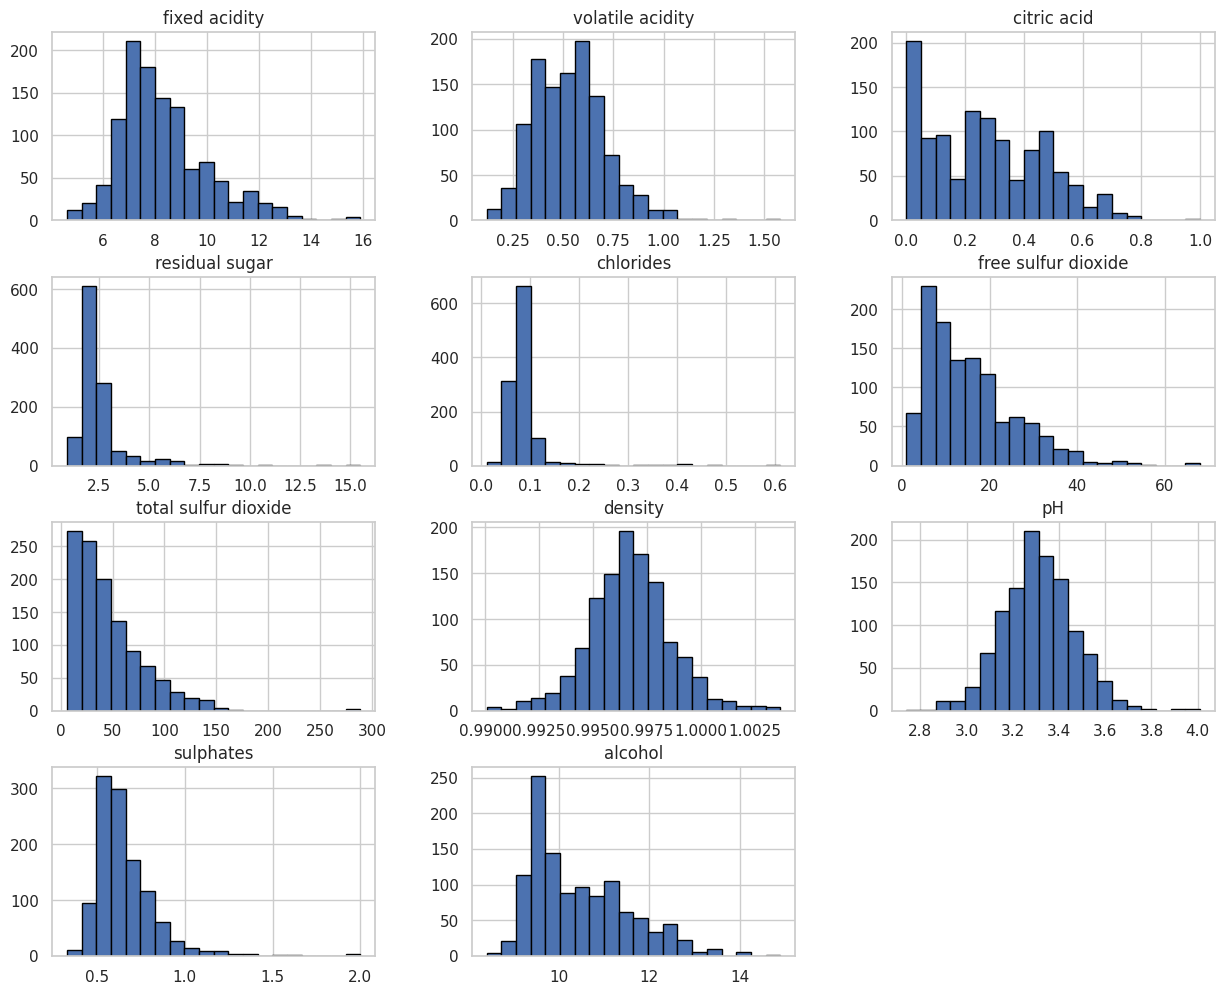

In [18]:
variaveis = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

df[variaveis].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

Esse código gera histogramas para as 11 características.

Permitindo identificar os principais padrões:

1) quais variáveis concentram a maior parte dos registros em determinadas faixas;
2) quais apresentam distribuições assimétricas;
3) quais possuem observações muito distantes da concentração principal.

Interpretação dos histogramas:

> Acidez fixa (fixed acidity)
A maior concentração de vinhos está entre aproximadamente 7 e 9. A distribuição apresenta assimetria à direita, com menor quantidade de amostras de acidez mais elevada.

> Acidez volátil (volatile acidity)
Os valores concentram-se principalmente entre 0,4 e 0,7. Há uma concentração central bem definida e uma cauda à direita, indicando poucas observações com acidez volátil elevada.

> Ácido cítrico (citric acid)
Existe concentração expressiva de observações próximas de zero, enquanto os demais valores estão distribuídos em diferentes faixas. A distribuição apresenta assimetria e dispersão considerável.

> Açúcar residual (residual sugar)
A maioria das observações está concentrada em valores baixos, especialmente próximos de 2 a 3. Há uma cauda longa à direita, indicando poucas amostras com concentrações significativamente maiores.

> Cloretos (chlorides)
Os valores estão fortemente concentrados em uma faixa estreita, próxima de 0,07 a 0,10. Algumas observações apresentam valores muito superiores à concentração predominante.

> Dióxido de enxofre livre (free sulfur dioxide)
A maior parte dos registros apresenta concentrações mais baixas, com redução gradual da frequência conforme os valores aumentam. A distribuição é assimétrica à direita.

> Dióxido de enxofre total (total sulfur dioxide)
Há predominância de concentrações mais baixas, com uma cauda extensa de valores elevados. Algumas observações apresentam concentrações bastante superiores às demais.

> Densidade (density)
Os valores apresentam distribuição aproximadamente simétrica, concentrada em torno de 0,997. A variação é relativamente pequena entre as amostras.

> pH
A distribuição apresenta concentração próxima de 3,3 e formato aproximadamente simétrico, indicando menor dispersão em comparação com algumas das demais variáveis.

> Sulfatos (sulphates)
A maior concentração está entre aproximadamente 0,5 e 0,8. A distribuição apresenta assimetria à direita e poucas observações com valores bastante elevados.

> Teor alcoólico (alcohol)
A maior parte das observações está concentrada entre aproximadamente 9% e 12%. A distribuição apresenta alguma assimetria à direita, com menor frequência de vinhos com teor alcoólico mais elevado.

## Análise de correlações

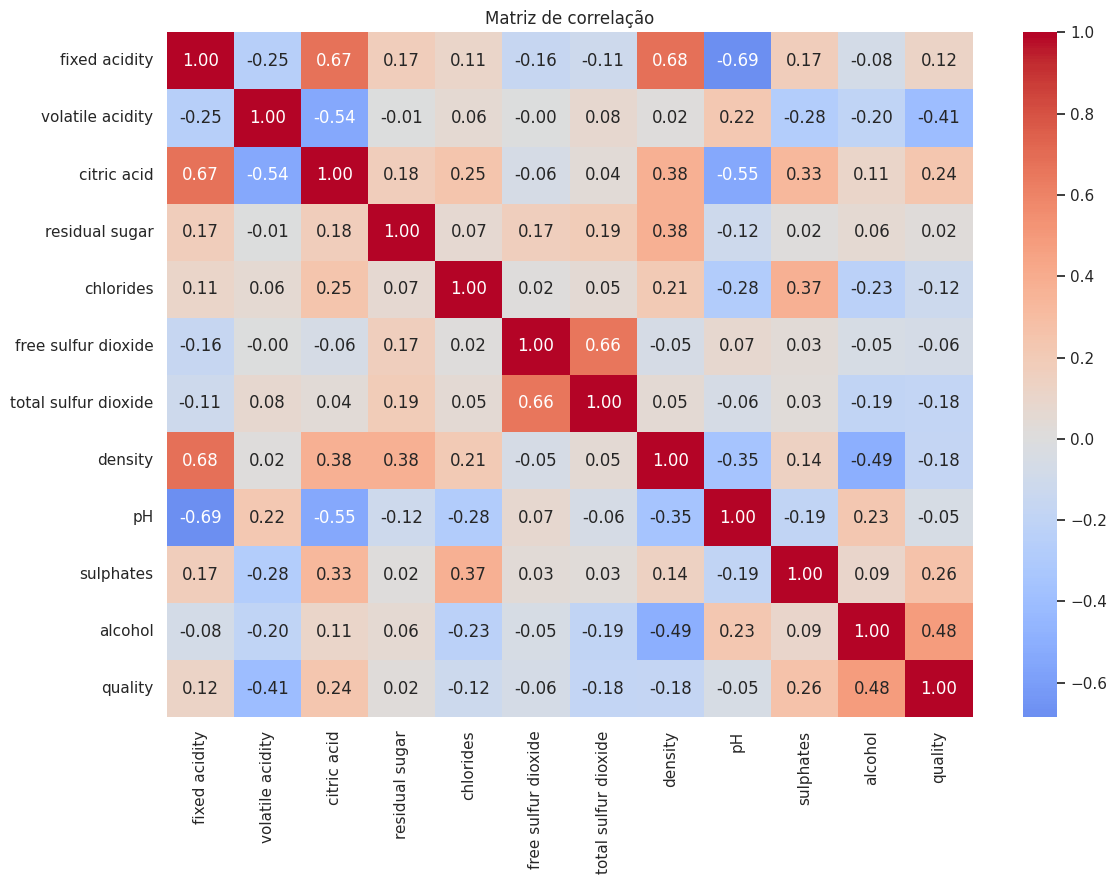

In [19]:
correlacao = df[variaveis + ["quality"]].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlação")

plt.tight_layout()

plt.savefig(
    "/content/matriz_correlacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Correlações com a qualidade
correlacao_quality = (
    correlacao["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

A análise de correlações tem como objetivo identificar quais características físico-químicas dos vinhos apresentam maior associação com as notas de qualidade e como essas características se relacionam entre si.

Em termos práticos, ela procura responder a duas perguntas:
1. Quais características tendem a estar mais associadas a vinhos com notas de qualidade mais elevadas?
2. Quais características apresentam comportamentos semelhantes ou relações entre si?
Essa análise é importante porque ajuda a compreender os dados antes de desenvolver os modelos de previsão.
3. Como interpretar a matriz de correlação?
Utilizamos uma matriz de correlação para medir a intensidade e a direção da relação entre duas variáveis.

Os valores variam de -1 a +1. Quanto mais próximo de -1 ou +1, mais forte é a associação linear. Quanto mais próximo de zero, mais fraca é essa associação.

Os quatro principais achados
> Teor alcoólico: correlação positiva de +0,48

É a característica com maior associação positiva com a qualidade.

Isso significa que, na base analisada, amostras com maior teor alcoólico tendem a apresentar notas de qualidade mais elevadas.

> Acidez volátil: correlação negativa de −0,41

É a característica com maior associação negativa.

Isso indica que amostras com maior acidez volátil tendem a apresentar notas de qualidade menores.

> Sulfatos: correlação positiva de +0,26

Apresentam uma associação positiva, embora mais fraca. Na base, concentrações maiores tendem a acompanhar notas de qualidade mais elevadas.

> Ácido cítrico: correlação positiva de +0,24

Também apresenta associação positiva fraca, indicando uma tendência de aumento conjunto com a nota de qualidade.

## Identificação de possíveis outliers

In [20]:
for coluna in variaveis:

    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(
        coluna,
        "- possíveis outliers:",
        len(outliers)
    )

fixed acidity - possíveis outliers: 44
volatile acidity - possíveis outliers: 14
citric acid - possíveis outliers: 1
residual sugar - possíveis outliers: 110
chlorides - possíveis outliers: 77
free sulfur dioxide - possíveis outliers: 18
total sulfur dioxide - possíveis outliers: 40
density - possíveis outliers: 36
pH - possíveis outliers: 20
sulphates - possíveis outliers: 43
alcohol - possíveis outliers: 12


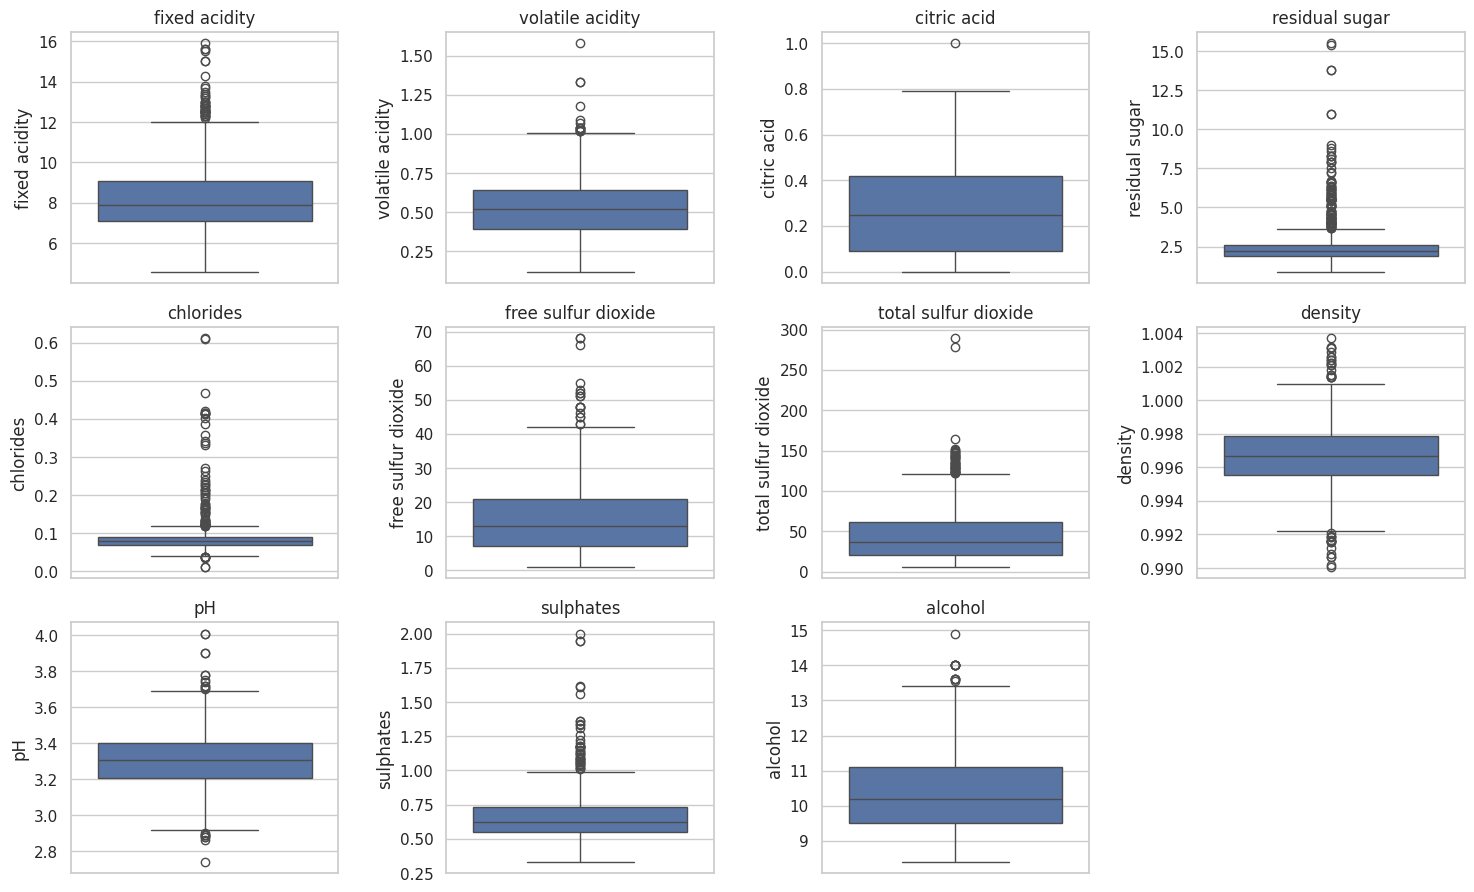

In [21]:
plt.figure(figsize=(15, 9))

for i, coluna in enumerate(variaveis, 1):

    plt.subplot(3, 4, i)

    sns.boxplot(y=df[coluna])

    plt.title(coluna)

plt.tight_layout()

plt.savefig(
    "/content/graficos_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Critério adotado:

Utilizado o método IQR para sinalizar observações potencialmente extremas.

Registros não eliminados automaticamente. Valores extremos podem ser características reais das amostras.

Não há evidências até o momento de que sejam erros, assim se manterá as observações.

## Avaliação do balanceamento das classes

Quantidade por classe:


,count
high_quality,
0,984
1,159


Percentual por classe:


,proportion
high_quality,
0,86.09
1,13.91


Text(0.5, 1.0, 'Distribuição das classes de qualidade')

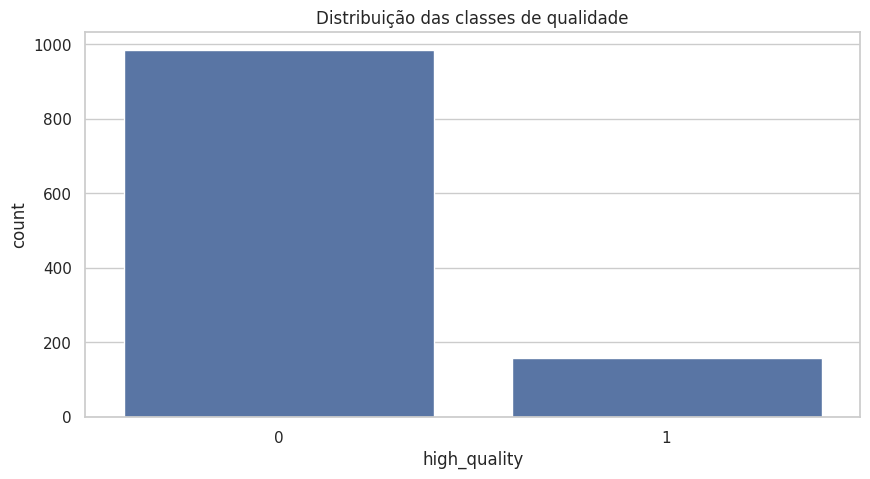

In [22]:
contagem_classes = df["high_quality"].value_counts()

percentual_classes = (
    df["high_quality"]
    .value_counts(normalize=True) * 100
)

print("Quantidade por classe:")
display(contagem_classes)

print("Percentual por classe:")
display(percentual_classes.round(2))

sns.countplot(
    data=df,
    x="high_quality"
)

plt.title("Distribuição das classes de qualidade")

Interpretação:

Existe um desbalanceamento significativo. A classe de alta qualidade representa apenas 13,9% das observações.

Essa característica será considerada durante o treinamento e a avaliação dos modelos.

## Gráficos: ajuste para incluir gráficos faltantes no arquivo de resultados

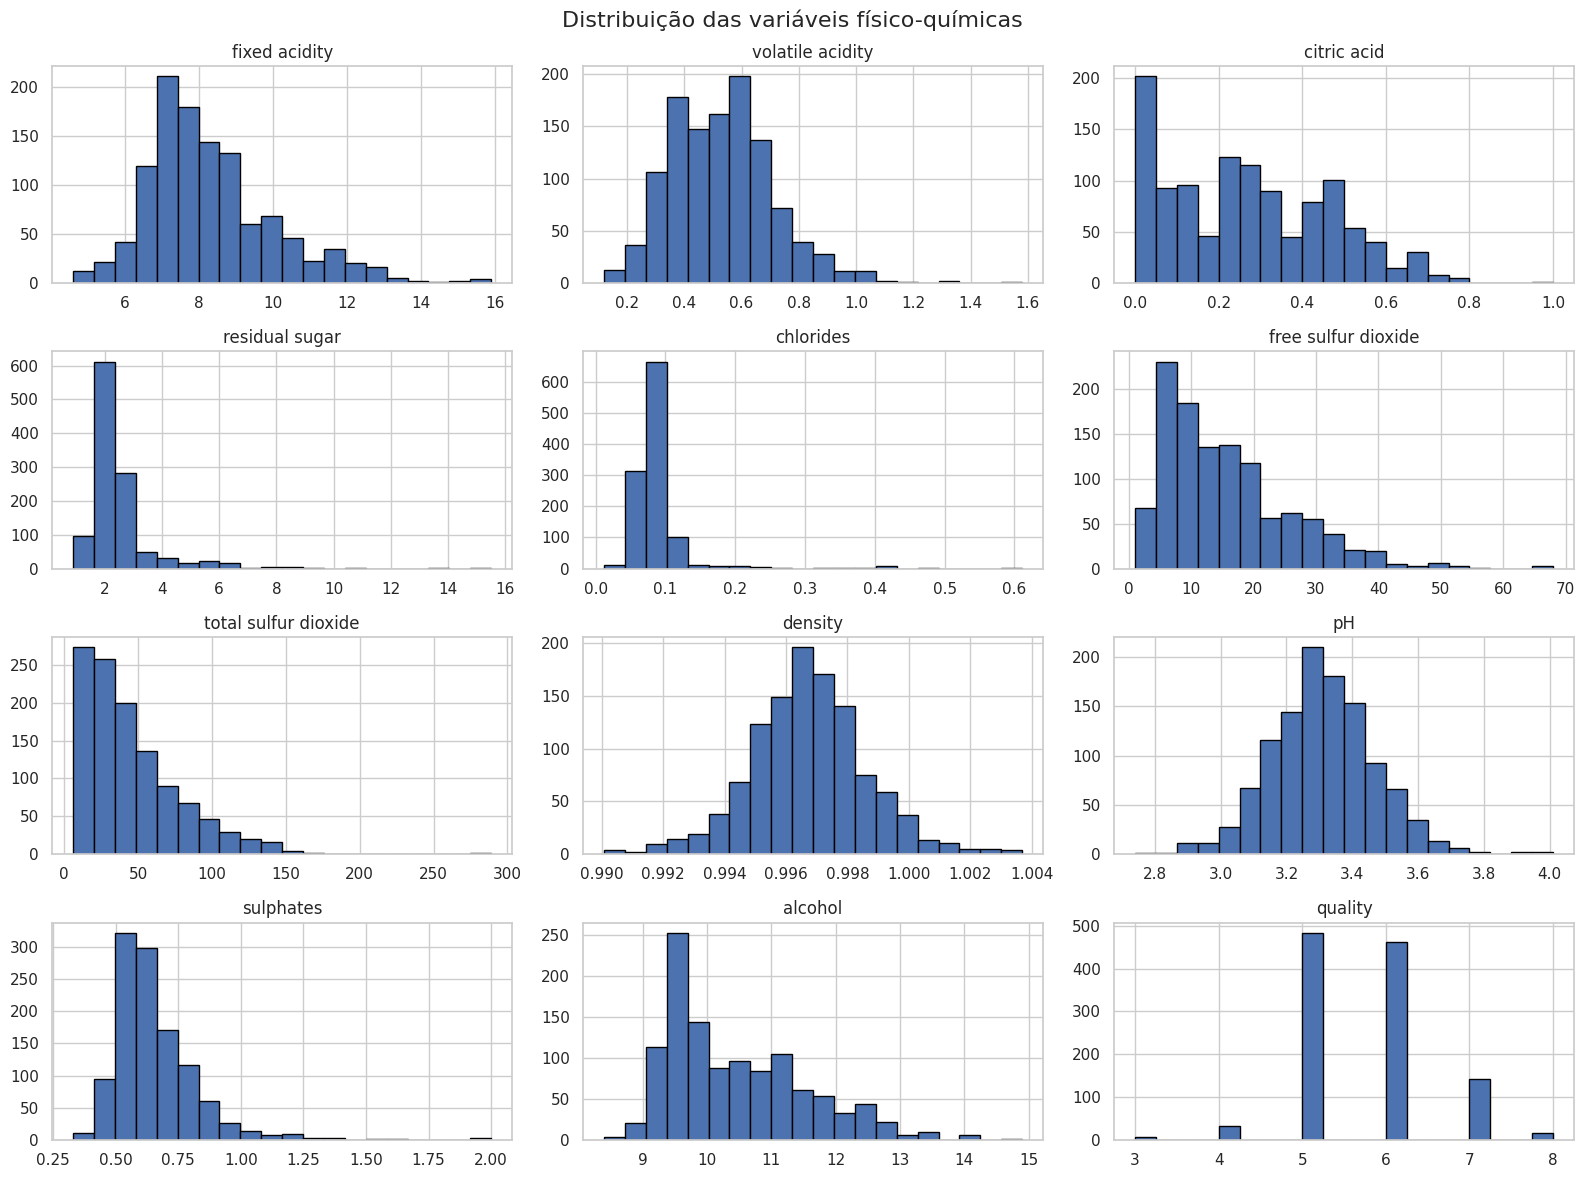

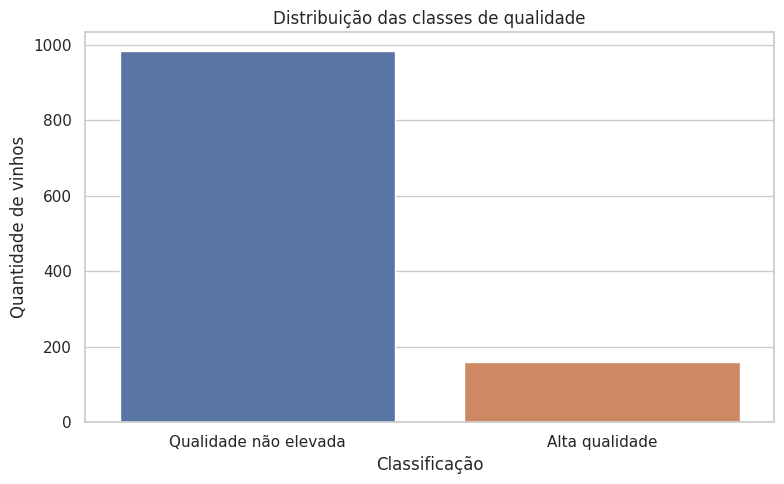

In [23]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Criar pasta de resultados, caso não exista
os.makedirs("results", exist_ok=True)

# Gráfico 1 - Distribuição das variáveis
variaveis = [
    col for col in df.select_dtypes(include="number").columns
    if col not in ["Id", "high_quality"]
]

df[variaveis].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribuição das variáveis físico-químicas",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "results/graficos_distribuicao.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# Gráfico 2 - Distribuição das classes
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="high_quality",
    hue="high_quality",
    legend=False
)

plt.title("Distribuição das classes de qualidade")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de vinhos")
plt.xticks([0, 1], ["Qualidade não elevada", "Alta qualidade"])

plt.tight_layout()
plt.savefig(
    "results/distribuicao_classes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

## Conclusões da análise exploratória

A base de dados contém 1.143 observações e 11 variáveis físico-químicas utilizadas para caracterizar as amostras de vinho.

Não foram identificados valores ausentes ou registros duplicados.

A análise das correlações evidenciou associação positiva entre o teor alcoólico e a qualidade, enquanto a acidez volátil apresentou associação negativa.

Foram identificados possíveis valores extremos em determinadas variáveis, os quais foram mantidos por não haver evidências suficientes de inconsistências.

Por fim, verificou-se desbalanceamento entre as classes, com predominância de amostras classificadas como baixa/média qualidade.

#4. Pré-processamento dos dados

## Critérios de preparação

Preparar os dados para que os algoritmos possam utilizá-los adequadamente.

Decisões:
1) Valores ausentes: Não há necessidade de tratamento.
2) Outliers: Serão mantidos, conforme análise anterior.
3) Padronização: Aplicada à regressão logística.
4) Identificador Id: Excluído das variáveis preditoras.
5) Nota quality: Excluída das variáveis preditoras, pois originou a classificação-alvo.
6) Novas variáveis: Não serão criadas, pois não foram identificadas necessidades que justifiquem essa etapa.

A padronização será realizada com StandardScaler:
Essa técnica ajusta a escala das variáveis numéricas, permitindo que características com magnitudes diferentes sejam utilizadas conjuntamente pelo algoritmo.

## Separação de variáveis preditoras e variáveis-alvo

In [24]:
# Variáveis preditoras
X = df.drop(
    columns=["quality", "high_quality", "Id"]
)

# Variável que queremos prever
y = df["high_quality"]

print("Variáveis preditoras:")
print(X.columns.tolist())

print("\nVariável-alvo:")
print(y.name)

print("\nDimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

Variáveis preditoras:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Variável-alvo:
high_quality

Dimensões de X: (1143, 11)
Dimensões de y: (1143,)


Interpretação:
Aqui temos,
- X: as 11 características físico-químicas.
- y: a classificação binária.
O identificador e a nota original não serão utilizados como entradas do modelo.

## Divisão da base entre treinamento e teste

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDistribuição da classe no treinamento:")
display(y_train.value_counts(normalize=True).round(3))

print("\nDistribuição da classe no teste:")
display(y_test.value_counts(normalize=True).round(3))

Treinamento: (914, 11)
Teste: (229, 11)

Distribuição da classe no treinamento:


,proportion
high_quality,
0,0.861
1,0.139



Distribuição da classe no teste:


,proportion
high_quality,
0,0.86
1,0.14


Interpretação: Reservamos 20% da base para avaliar sua capacidade de classificar amostras que não participaram do treinamento.

A utilização de stratify=y preserva a proporção das classes nos dois conjuntos.


#5. Desenvolvimento dos modelos


## Treinamento do primeiro modelo: Regressão Logística

In [26]:
modelo_logistico = Pipeline([
    ("padronizacao", StandardScaler()),

    ("modelo", LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

modelo_logistico.fit(X_train, y_train)

print("Regressão Logística treinada com sucesso!")

Regressão Logística treinada com sucesso!


A Regressão Logística é um algoritmo utilizado para classificação.

Ele estima a probabilidade de uma observação pertencer a determinada categoria.

Nesse caso, estima a probabilidade de um vinho pertencer à categoria de alta qualidade.

É uma abordagem que servirá como referência para comparar os resultados de outro algoritmo.

A padronização está incorporada ao processo de treinamento, evitando que o cálculo das escalas utilize informações do conjunto de teste.

O parâmetro class_weight="balanced" atribui pesos diferenciados às classes, considerando o desbalanceamento identificado na análise exploratória dos dados.

## Treinamento do segundo modelo: Random Forest

In [27]:
modelo_floresta = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

modelo_floresta.fit(X_train, y_train)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


Random Forest é um algoritmo que combina várias árvores de decisão.

Cada árvore realiza classificações com base em diferentes combinações das características disponíveis, e o conjunto das árvores produz a previsão final.

Utilizaremos 200 árvores de decisão.

Também aplicaremos o balanceamento das classes.


#6. Avaliação e comparação dos modelos


## Calculando as métricas de desempenho

In [28]:
modelos = {
    "Regressão Logística": modelo_logistico,
    "Random Forest": modelo_floresta
}

resultados = []

for nome, modelo in modelos.items():

    previsoes = modelo.predict(X_test)

    probabilidades = modelo.predict_proba(X_test)[:, 1]

    resultados.append({
        "Modelo": nome,

        "Acurácia": accuracy_score(
            y_test, previsoes
        ),

        "Precisão": precision_score(
            y_test, previsoes, zero_division=0
        ),

        "Recall": recall_score(
            y_test, previsoes, zero_division=0
        ),

        "F1-score": f1_score(
            y_test, previsoes, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test, probabilidades
        )
    })

comparacao = pd.DataFrame(resultados)

display(comparacao.round(3))

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC
0,Regressão Logística,0.799,0.379,0.688,0.489,0.850
1,Random Forest,0.908,0.762,0.500,0.604,0.905


Verificamos aqui como os dois modelos se comportam diante das amostras reservadas para teste.

Indicadores:
1) Acurácia - Proporção de classificações corretas no total.
2) Precisão - Proporção de acertos entre as amostras classificadas como alta qualidade.
3) Recall - Proporção de amostras realmente de alta qualidade que foram identificadas.
4) F1-score -	Equilíbrio entre precisão e recall.
5) ROC-AUC - Capacidade de distinguir as duas classes considerando diferentes limiares de decisão.

Como interpretar os resultados:
- Precisão maior: menor proporção de falsos positivos entre os vinhos classificados como alta qualidade.
- Recall maior: maior capacidade de identificar os vinhos realmente classificados como alta qualidade.
- F1-score maior: melhor equilíbrio entre precisão e recall.
- ROC-AUC maior: melhor capacidade de discriminar as classes.

Para este estudo, vamos priorizar o equilíbrio entre precisão e recall, considerando o F1-score, e utilizar ROC-AUC como indicador complementar.

Não devemos considerar apenas a acurácia. Pois, se um modelo classificasse todos os vinhos como baixa/média qualidade, acertaria aproximadamente 86% das amostras, mas não identificaria nenhum vinho de alta qualidade.

Por fim, temos uma tabela com os indicadores de desempenho dos dois modelos.

## Criando uma matriz de confusão

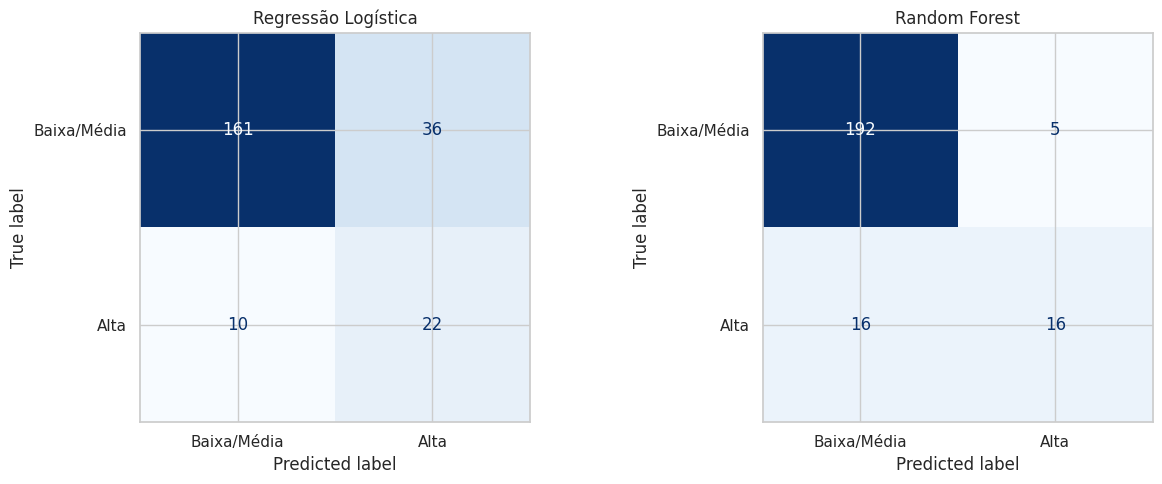

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (nome, modelo) in zip(axes, modelos.items()):

    previsoes = modelo.predict(X_test)

    matriz = confusion_matrix(
        y_test,
        previsoes
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=[
            "Baixa/Média",
            "Alta"
        ]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(nome)

plt.tight_layout()

plt.savefig(
    "/content/matrizes_confusao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

A matriz de confusão apresenta a quantidade de classificações corretas e incorretas.

Vamos focar na interpretação dos resultados referentes à classe de alta qualidade.

- Quantos vinhos de alta qualidade foram identificados corretamente.
- Quantos vinhos de alta qualidade não foram identificados.
- Quantos vinhos foram classificados como alta qualidade incorretamente.

Essas informações ajudam a avaliar os riscos associados à utilização de cada modelo.

## Relatórios individuais

In [30]:
for nome, modelo in modelos.items():

    print("\n", "=" * 50)
    print(nome)
    print("=" * 50)

    previsoes = modelo.predict(X_test)

    print(
        classification_report(
            y_test,
            previsoes,
            target_names=[
                "Baixa/Média qualidade",
                "Alta qualidade"
            ],
            zero_division=0
        )
    )


Regressão Logística
                       precision    recall  f1-score   support

Baixa/Média qualidade       0.94      0.82      0.88       197
       Alta qualidade       0.38      0.69      0.49        32

             accuracy                           0.80       229
            macro avg       0.66      0.75      0.68       229
         weighted avg       0.86      0.80      0.82       229


Random Forest
                       precision    recall  f1-score   support

Baixa/Média qualidade       0.92      0.97      0.95       197
       Alta qualidade       0.76      0.50      0.60        32

             accuracy                           0.91       229
            macro avg       0.84      0.74      0.78       229
         weighted avg       0.90      0.91      0.90       229



Esse relatório apresenta precisão, recall e F1-score para cada uma das duas classes, além das médias.

É importante verificar também o desempenho da classe 0, pois um modelo não deve ser avaliado apenas pela capacidade de identificar a classe minoritária.

## Gráfico comparativo entre os modelos

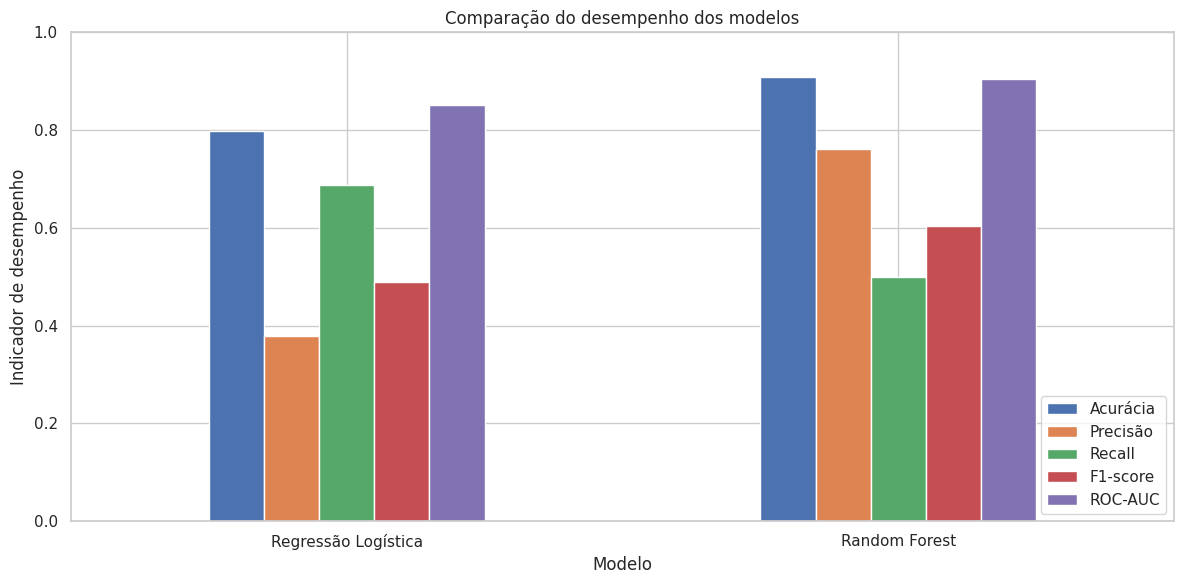

In [31]:
comparacao_grafico = comparacao.set_index("Modelo")

comparacao_grafico[
    ["Acurácia", "Precisão", "Recall", "F1-score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparação do desempenho dos modelos")

plt.ylabel("Indicador de desempenho")

plt.xlabel("Modelo")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "/content/comparacao_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Variáveis mais importantes

,Variável,Importância
10,alcohol,0.2139
2,citric acid,0.1437
9,sulphates,0.1424
1,volatile acidity,0.1091
7,density,0.0749
6,total sulfur dioxide,0.0652
0,fixed acidity,0.0613
4,chlorides,0.0531
8,pH,0.0522
3,residual sugar,0.0444


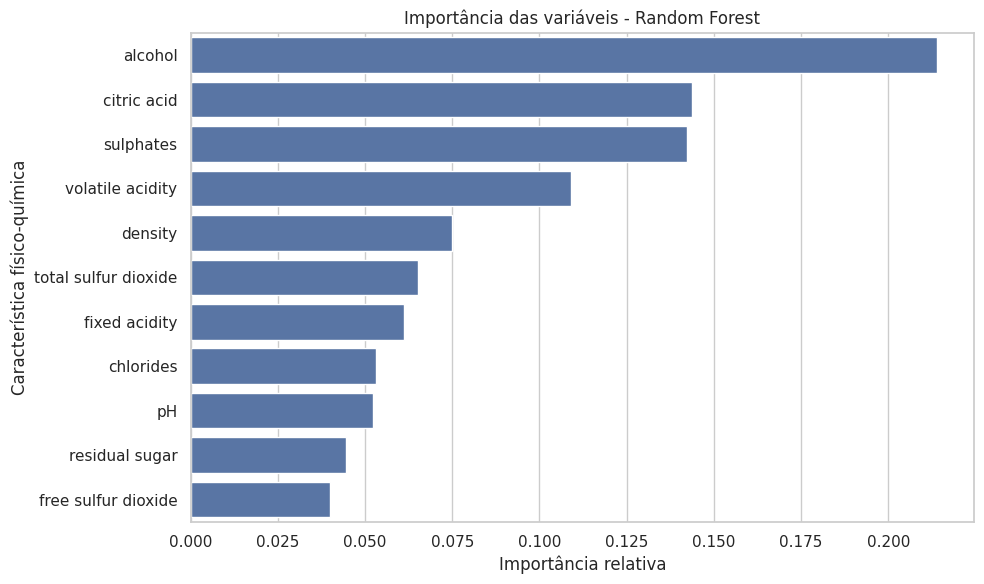

In [32]:
importancias = pd.DataFrame({
    "Variável": X_train.columns,
    "Importância": modelo_floresta.feature_importances_
})

importancias = importancias.sort_values(
    by="Importância",
    ascending=False
)

display(importancias.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancias,
    x="Importância",
    y="Variável"
)

plt.title(
    "Importância das variáveis - Random Forest"
)

plt.xlabel("Importância relativa")

plt.ylabel("Característica físico-química")

plt.tight_layout()

plt.savefig(
    "/content/importancia_variaveis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Utilizamos o Random Forest para identificar a importância relativa das características físico-químicas nas previsões.

Quais características foram mais relevantes para as decisões realizadas pelo Random Forest.

O resultado aponta maior importância do teor alcoólico ou do ácido cítrico.

Entretanto, não devemos afirmar que essas características causam diretamente a qualidade.

O gráfico demonstra sua relevância para as previsões realizadas pelo algoritmo.

#7. Interpretação dos resultados

## Tabela de resultados

In [33]:
# Organizar os resultados
comparacao_final = comparacao.copy()

comparacao_final = comparacao_final.round(4)

# Salvar os resultados em CSV
comparacao_final.to_csv(
    "/content/resultados_modelos.csv",
    index=False
)

# Salvar a importância das variáveis
importancias.to_csv(
    "/content/importancia_variaveis.csv",
    index=False
)

print("Resultados salvos com sucesso!")

display(comparacao_final)

Resultados salvos com sucesso!


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC
0,Regressão Logística,0.7991,0.3793,0.6875,0.4889,0.8504
1,Random Forest,0.9083,0.7619,0.5000,0.6038,0.9054


Preservamos os resultados numéricos para utilizá-los na apresentação executiva e no README.

## Avaliando o modelo de melhor desempenho

In [34]:
melhor_modelo_nome = (
    comparacao
    .sort_values(
        by=["F1-score", "ROC-AUC"],
        ascending=False
    )
    .iloc[0]["Modelo"]
)

print(
    "Modelo com melhor F1-score e desempate por ROC-AUC:",
    melhor_modelo_nome
)

Modelo com melhor F1-score e desempate por ROC-AUC: Random Forest


Adotando o F1-score como critério principal de comparação, observando conjuntamente precisão, recall e ROC-AUC.

Essa regra serve para organizar a comparação, não para afirmar que o modelo escolhido é necessariamente o mais adequado para qualquer aplicação empresarial.

A decisão deverá considerar também os erros identificados na matriz de confusão.

#8. Conclusões

A análise demonstrou que a base de dados apresenta características adequadas para a realização do estudo, não tendo sido identificados valores ausentes ou registros duplicados.

A análise exploratória identificou associações entre determinadas características físico-químicas e as notas de qualidade, com destaque para o "alcohol" e "citric acid".

Foram desenvolvidos dois modelos de classificação: Regressão Logística e Random Forest.

Na comparação dos resultados, o modelo Random Forest apresentou o maior F1-score, de 0.6038, e ROC-AUC de 0.9054.

As características mais relevantes para as previsões foram "alcohol" e "citric acid".

Os resultados indicam potencial de utilização de modelos preditivos como ferramentas complementares para apoiar o monitoramento e o controle da qualidade dos vinhos.

Entretanto, o estudo apresenta limitações relacionadas ao tamanho da base, ao desbalanceamento das classes e à utilização de características físico-químicas como preditoras de uma avaliação originalmente sensorial.

O modelo não substitui a avaliação dos especialistas, devendo ser considerado um instrumento complementar de apoio à decisão.

## Pasta de resultados

In [35]:
import os

os.makedirs("/content/results", exist_ok=True)

arquivos = [
    "graficos_distribuicao.png",
    "matriz_correlacao.png",
    "graficos_outliers.png",
    "distribuicao_classes.png",
    "matrizes_confusao.png",
    "comparacao_modelos.png",
    "importancia_variaveis.png",
    "resultados_modelos.csv",
    "importancia_variaveis.csv"
]

for arquivo in arquivos:

    origem = "/content/" + arquivo
    destino = "/content/results/" + arquivo

    if os.path.exists(origem):
        import shutil
        shutil.copy(origem, destino)

print("Pasta de resultados organizada!")

Pasta de resultados organizada!


## Arquivo compactado

In [36]:
import shutil

# Compactar novamente a pasta results
shutil.make_archive(
    "/content/resultados_fase_2",
    "zip",
    "results"
)

print("Arquivo ZIP atualizado com sucesso!")

Arquivo ZIP atualizado com sucesso!
